# Assignment 2: Exploratory Data Analysis, Outlier Analysis, and DBSCAN Anomaly Detection
**Dataset**: `Fraud Detection Dataset.csv`

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
print("Environment initialized successfully.")

Environment initialized successfully.


In [2]:
# Load dataset and print shape & head
df = pd.read_csv("Fraud Detection Dataset.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (51000, 12)


In [3]:
# List dataset columns
print("Columns List:")
print(df.columns.tolist())

Columns List:
['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type', 'Time_of_Transaction', 'Device_Used', 'Location', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent']


In [4]:
# Demonstrating dropna
df_demo = df.dropna()
print("Shape after dropping missing rows:", df_demo.shape)

Shape after dropping missing rows: (39583, 12)


In [5]:
# Missing values percentage per column
missing_percent = df.isnull().mean() * 100
print("--- Missing Percentage per Column ---")
print(missing_percent)

--- Missing Percentage per Column ---
Transaction_ID                      0.000000
User_ID                             0.000000
Transaction_Amount                  4.941176
Transaction_Type                    0.000000
Time_of_Transaction                 5.003922
Device_Used                         4.849020
Location                            4.994118
Previous_Fraudulent_Transactions    0.000000
Account_Age                         0.000000
Number_of_Transactions_Last_24H     0.000000
Payment_Method                      4.841176
Fraudulent                          0.000000
dtype: float64


In [6]:
# Overall duplicate rows count
duplicates = df.duplicated().sum()
print("Total Exact Duplicate Records:", duplicates)

Total Exact Duplicate Records: 881


### Task 1: Column wise Duplicate count
Calculating the number of duplicate/repeated entries per column.

--- Column-wise Duplicate Count Table ---
                          Column  Total Non-Null  Unique Values  Duplicate Entries  Duplicate %
                  Transaction_ID           51000          50000               1000         1.96
                         User_ID           51000           4000              47000        92.16
              Transaction_Amount           48480          44821               3659         7.55
                Transaction_Type           51000              5              50995        99.99
             Time_of_Transaction           48448             24              48424        99.95
                     Device_Used           48527              4              48523        99.99
                        Location           48453              8              48445        99.98
Previous_Fraudulent_Transactions           51000              5              50995        99.99
                     Account_Age           51000            119              50881        99.7

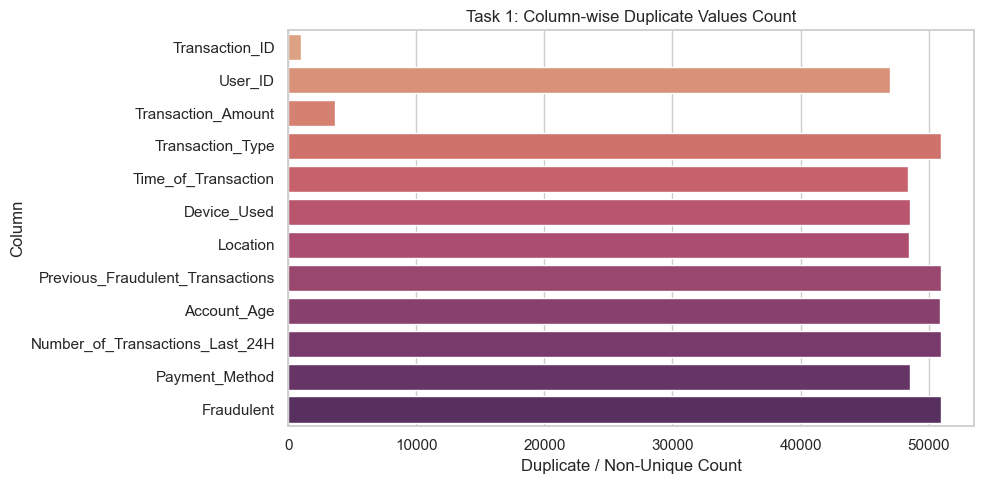

In [7]:
# Task 1: Column-wise duplicate values count
col_dup_list = []
for col in df.columns:
    total_val = len(df[col].dropna())
    uniq_val = df[col].nunique(dropna=True)
    dup_val = total_val - uniq_val
    col_dup_list.append({
        "Column": col,
        "Total Non-Null": total_val,
        "Unique Values": uniq_val,
        "Duplicate Entries": dup_val,
        "Duplicate %": round((dup_val / total_val) * 100, 2) if total_val > 0 else 0
    })

col_dup_df = pd.DataFrame(col_dup_list)
print("--- Column-wise Duplicate Count Table ---")
print(col_dup_df.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=col_dup_df, x="Duplicate Entries", y="Column", palette="flare")
plt.title("Task 1: Column-wise Duplicate Values Count")
plt.xlabel("Duplicate / Non-Unique Count")
plt.tight_layout()
plt.show()

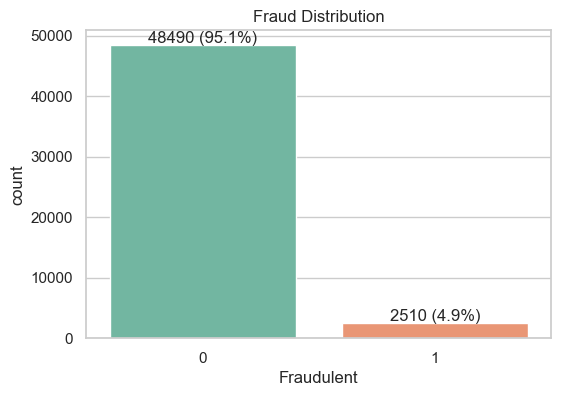

In [8]:
# Fraud distribution visualization
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Fraudulent", data=df, palette="Set2")
plt.title("Fraud Distribution")
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{int(h)} ({h/len(df)*100:.1f}%)', 
                (p.get_x() + p.get_width() / 2., h), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

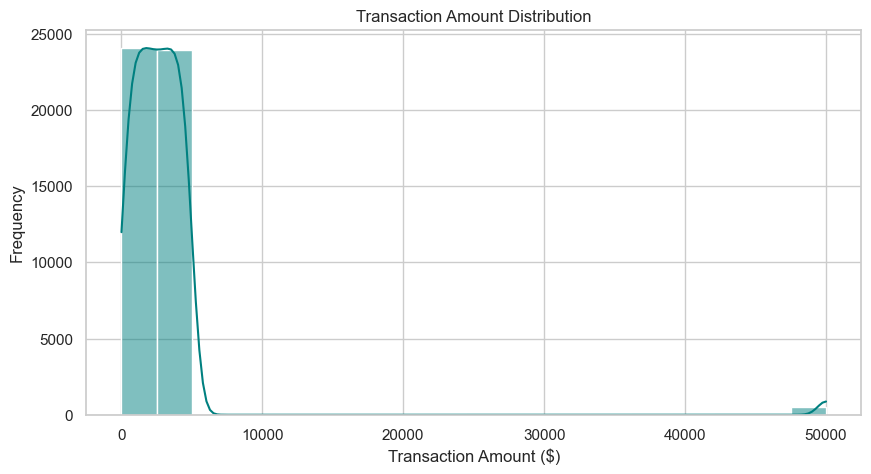

In [9]:
# Transaction Amount Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["Transaction_Amount"], bins=20, kde=True, color="teal")
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount ($)")
plt.ylabel("Frequency")
plt.show()

### Task 2: Cluster for Payment_Method v/s Fraudulent
Analyzing fraud rates across payment methods and performing statistical chi-square test.

--- Crosstab: Payment Method vs Fraudulent ---
Fraudulent          0     1    All
Payment_Method                    
Credit Card     11072   574  11646
Debit Card      11230   572  11802
Invalid Method   1457    73   1530
Missing          2364   105   2469
Net Banking     11092   574  11666
UPI             11275   612  11887
All             48490  2510  51000

--- Fraud Percentage (%) per Payment Method ---
Fraudulent              0         1
Payment_Method                     
Credit Card     95.071269  4.928731
Debit Card      95.153364  4.846636
Invalid Method  95.228758  4.771242
Missing         95.747266  4.252734
Net Banking     95.079719  4.920281
UPI             94.851518  5.148482
Chi-Square Independence Test (Payment Method vs Fraud): Stat = 3.885, p-val = 5.6607e-01


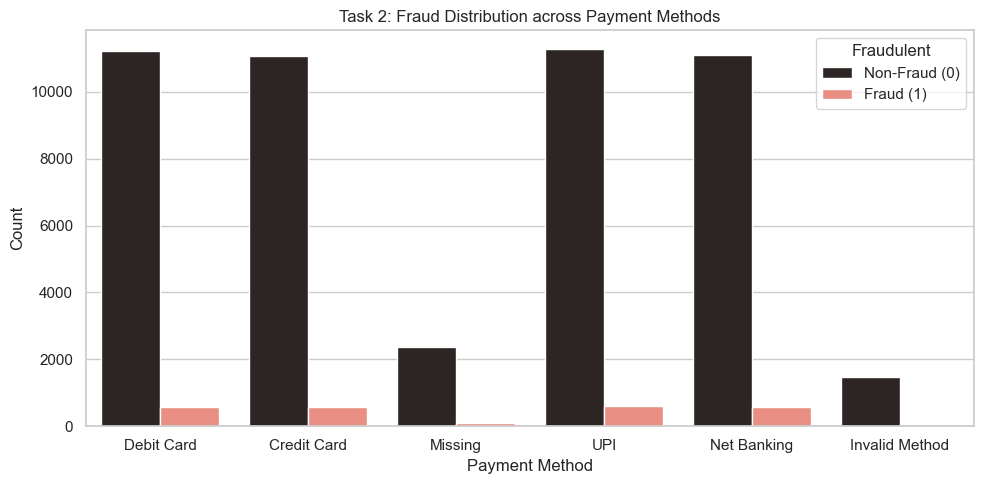

In [10]:
# Task 2 (Part A): Payment_Method v/s Fraudulent Cross Analysis
df_pm = df.copy()
df_pm["Payment_Method"] = df_pm["Payment_Method"].fillna("Missing")

ct = pd.crosstab(df_pm["Payment_Method"], df_pm["Fraudulent"], margins=True)
print("--- Crosstab: Payment Method vs Fraudulent ---")
print(ct)

ct_pct = pd.crosstab(df_pm["Payment_Method"], df_pm["Fraudulent"], normalize='index') * 100
print("\n--- Fraud Percentage (%) per Payment Method ---")
print(ct_pct)

plt.figure(figsize=(10, 5))
sns.countplot(data=df_pm, x="Payment_Method", hue="Fraudulent", palette="dark:salmon")
plt.title("Task 2: Fraud Distribution across Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Count")
plt.legend(title="Fraudulent", labels=["Non-Fraud (0)", "Fraud (1)"])
plt.tight_layout()
plt.show()

# Chi-Square Test
chi2_stat, p_val, dof, ex = chi2_contingency(pd.crosstab(df_pm["Payment_Method"], df_pm["Fraudulent"]))
print(f"Chi-Square Independence Test (Payment Method vs Fraud): Stat = {chi2_stat:.3f}, p-val = {p_val:.4e}")

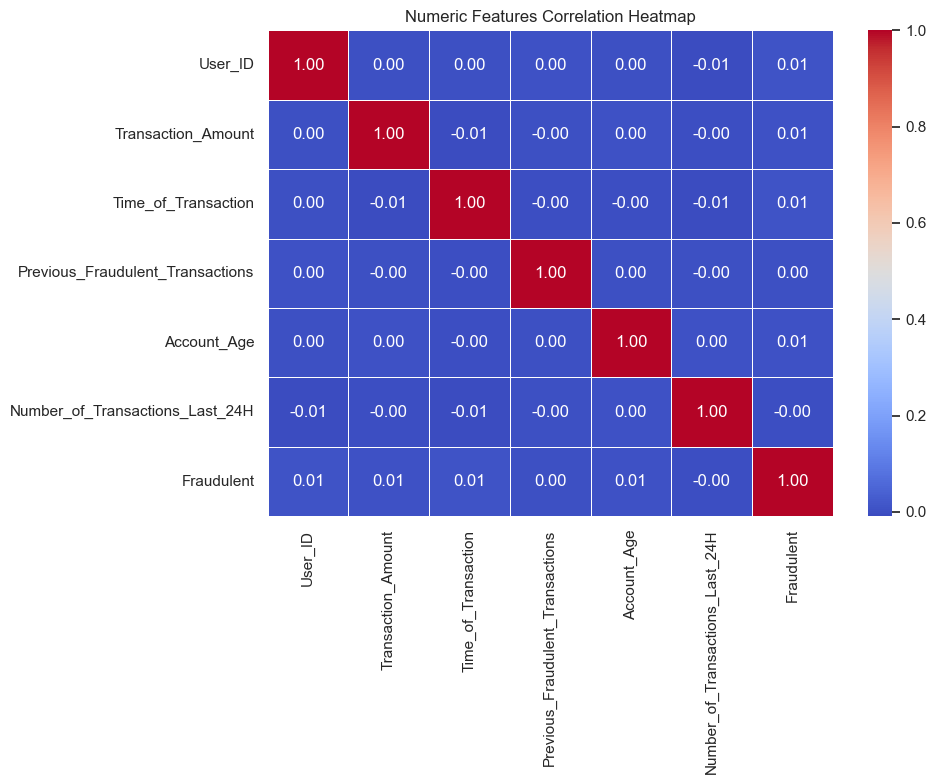

In [11]:
# Correlation Heatmap for numeric features
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Numeric Features Correlation Heatmap")
plt.tight_layout()
plt.show()

# Outlier Analysis
Evaluating outliers in `Transaction_Amount` using Interquartile Range (IQR).

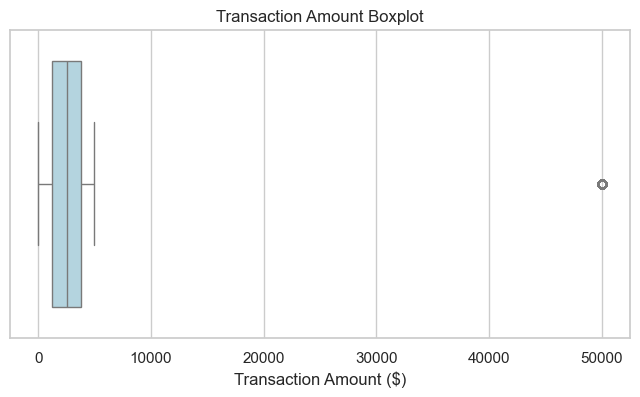

In [12]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Transaction_Amount"], color="lightblue")
plt.title("Transaction Amount Boxplot")
plt.xlabel("Transaction Amount ($)")
plt.show()

In [13]:
# Outliers calculation for Transaction_Amount
Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Transaction_Amount"] < lower) | (df["Transaction_Amount"] > upper)]
print(f"Transaction_Amount IQR Bounds -> Q1: {Q1:.2f}, Q3: {Q3:.2f}, Lower: {lower:.2f}, Upper: {upper:.2f}")
print(f"Outliers Count: {outliers.shape[0]} ({outliers.shape[0]/len(df)*100:.2f}%)")
outliers.head()

Transaction_Amount IQR Bounds -> Q1: 1270.55, Q3: 3787.24, Lower: -2504.48, Upper: 7562.27
Outliers Count: 508 (1.00%)


### Task 2: Find Outliers from Time_of_Transaction, and create graph
Analyzing outliers in `Time_of_Transaction` feature.

Time_of_Transaction IQR Bounds -> Lower: -13.00, Upper: 35.00
Outliers Count via IQR: 0


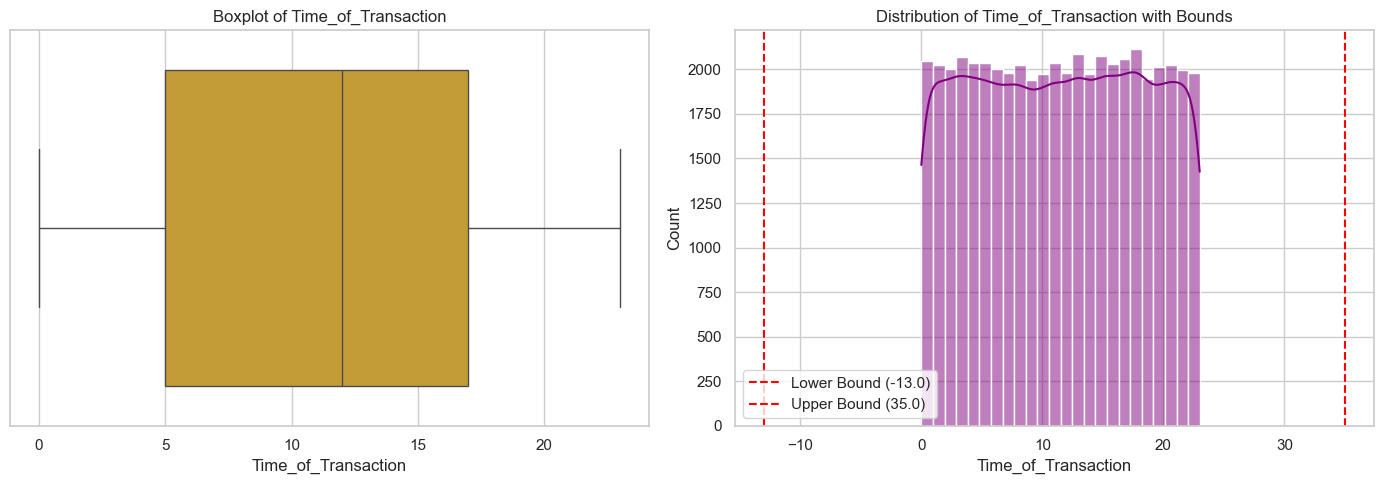

In [14]:
# Task 2 (Part B): Outliers for Time_of_Transaction
tot = df["Time_of_Transaction"].dropna()
q1_t = tot.quantile(0.25)
q3_t = tot.quantile(0.75)
iqr_t = q3_t - q1_t
lower_t = q1_t - 1.5 * iqr_t
upper_t = q3_t + 1.5 * iqr_t

tot_outliers = df[(df["Time_of_Transaction"] < lower_t) | (df["Time_of_Transaction"] > upper_t)]
print(f"Time_of_Transaction IQR Bounds -> Lower: {lower_t:.2f}, Upper: {upper_t:.2f}")
print(f"Outliers Count via IQR: {tot_outliers.shape[0]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df["Time_of_Transaction"], ax=axes[0], color="goldenrod")
axes[0].set_title("Boxplot of Time_of_Transaction")

sns.histplot(df["Time_of_Transaction"], bins=24, kde=True, ax=axes[1], color="purple")
axes[1].axvline(lower_t, color='red', linestyle='--', label=f'Lower Bound ({lower_t:.1f})')
axes[1].axvline(upper_t, color='red', linestyle='--', label=f'Upper Bound ({upper_t:.1f})')
axes[1].set_title("Distribution of Time_of_Transaction with Bounds")
axes[1].legend()

plt.tight_layout()
plt.show()

### Task 3: Identify Uncommon/Common Value/s
Identifying common (frequent) and uncommon (rare) values across attributes.

In [15]:
# Task 3: Uncommon/Common values analysis
print("--- Most Common & Uncommon Categories per Feature ---")
for col in ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]:
    vc = df[col].value_counts(dropna=False)
    print(f"\nFeature: {col}")
    print(f"  Top Most Common: {vc.head(2).to_dict()}")
    print(f"  Uncommon / Rare: {vc.tail(2).to_dict()}")

print("\n--- Common Ranges & Extremes for Numerical Attributes ---")
for col in ["Transaction_Amount", "Time_of_Transaction", "Account_Age", "Number_of_Transactions_Last_24H"]:
    print(f"{col} -> Min: {df[col].min()}, Median: {df[col].median():.2f}, Max: {df[col].max()}")

--- Most Common & Uncommon Categories per Feature ---

Feature: Transaction_Type
  Top Most Common: {'Bill Payment': 10340, 'Bank Transfer': 10276}
  Uncommon / Rare: {'POS Payment': 10126, 'Online Purchase': 10094}

Feature: Device_Used
  Top Most Common: {'Desktop': 15795, 'Mobile': 15614}
  Uncommon / Rare: {nan: 2473, 'Unknown Device': 1530}

Feature: Location
  Top Most Common: {'Boston': 6149, 'New York': 6110}
  Uncommon / Rare: {'San Francisco': 5985, nan: 2547}

Feature: Payment_Method
  Top Most Common: {'UPI': 11887, 'Debit Card': 11802}
  Uncommon / Rare: {nan: 2469, 'Invalid Method': 1530}

--- Common Ranges & Extremes for Numerical Attributes ---
Transaction_Amount -> Min: 5.03, Median: 2524.10, Max: 49997.8
Time_of_Transaction -> Min: 0.0, Median: 12.00, Max: 23.0
Account_Age -> Min: 1, Median: 60.00, Max: 119
Number_of_Transactions_Last_24H -> Min: 1, Median: 7.00, Max: 14


In [16]:
# DBSCAN Setup - Base Features Selection
features = [
    "Transaction_Amount",
    "Previous_Fraudulent_Transactions",
    "Account_Age",
    "Number_of_Transactions_Last_24H"
]

df_base = df.copy()
for col in features:
    df_base[col] = df_base[col].fillna(df_base[col].median())

In [17]:
# Feature Scaling
X_base = df_base[features]
scaler = StandardScaler()
X_base_scaled = scaler.fit_transform(X_base)

In [18]:
# Fit DBSCAN Cluster Model
dbscan = DBSCAN(eps=0.8, min_samples=15)
labels = dbscan.fit_predict(X_base_scaled)

In [19]:
# Assign Clusters to Dataframe
df_base["Cluster"] = labels
print("Base DBSCAN Cluster Distribution:")
print(df_base["Cluster"].value_counts())
print(f"Total Base Noise/Anomalies (Cluster = -1): {(df_base['Cluster'] == -1).sum()}")

Base DBSCAN Cluster Distribution:
Cluster
 0    50492
 1      505
-1        3
Name: count, dtype: int64
Total Base Noise/Anomalies (Cluster = -1): 3


### Task 4: Identify Anomalies with -1 (for different feature set)
Performing DBSCAN anomaly detection using an expanded feature set.

In [20]:
# Task 4: DBSCAN Anomaly Detection with Alternative Feature Set
alt_features = [
    "Transaction_Amount",
    "Time_of_Transaction",
    "Previous_Fraudulent_Transactions",
    "Account_Age",
    "Number_of_Transactions_Last_24H"
]

df_alt = df.copy()
for col in alt_features:
    df_alt[col] = df_alt[col].fillna(df_alt[col].median())

X_alt = df_alt[alt_features]
scaler_alt = StandardScaler()
X_alt_scaled = scaler_alt.fit_transform(X_alt)

dbscan_alt = DBSCAN(eps=0.9, min_samples=20)
labels_alt = dbscan_alt.fit_predict(X_alt_scaled)
df_alt["Cluster"] = labels_alt

print("--- Alternative DBSCAN Cluster Counts ---")
print(df_alt["Cluster"].value_counts())

anomalies_alt = df_alt[df_alt["Cluster"] == -1]
normal_alt = df_alt[df_alt["Cluster"] != -1]

print(f"\nAlternative DBSCAN Anomalies Count: {len(anomalies_alt)} ({len(anomalies_alt)/len(df_alt)*100:.2f}%)")
print(f"Fraud Rate in Anomalies (Cluster = -1): {anomalies_alt['Fraudulent'].mean()*100:.2f}%")
print(f"Fraud Rate in Normal Clusters: {normal_alt['Fraudulent'].mean()*100:.2f}%")

print("\nSample Alternative Anomaly Records:")
print(anomalies_alt[alt_features + ["Fraudulent"]].head(10).to_string())

--- Alternative DBSCAN Cluster Counts ---
Cluster
 0    50492
-1      470
 1       38
Name: count, dtype: int64

Alternative DBSCAN Anomalies Count: 470 (0.92%)
Fraud Rate in Anomalies (Cluster = -1): 6.38%
Fraud Rate in Normal Clusters: 4.91%

Sample Alternative Anomaly Records:
     Transaction_Amount  Time_of_Transaction  Previous_Fraudulent_Transactions  Account_Age  Number_of_Transactions_Last_24H  Fraudulent
166             49997.8                  3.0                                 3          108                                8           0
236             49997.8                  3.0                                 3          103                                6           0
245             49997.8                  1.0                                 3           78                                9           0
298             49997.8                 18.0                                 2           85                                2           0
317             49997.8           

In [21]:
# Display Base DBSCAN Suspicious Anomaly Records
suspicious = df_base[df_base["Cluster"] == -1]
print("Suspicious Base Anomaly Records (Head):")
print(suspicious.head())

Suspicious Base Anomaly Records (Head):
      Transaction_ID  User_ID  ...  Fraudulent Cluster
15441         T15442     4030  ...           0      -1
28247         T28248     1065  ...           0      -1
34603         T34604     1646  ...           0      -1

[3 rows x 13 columns]


### Task 5: Create Graphs for Anomalies / Cluster Graph (any two attributes)
Visualizing DBSCAN clusters and anomalies across feature pairs.

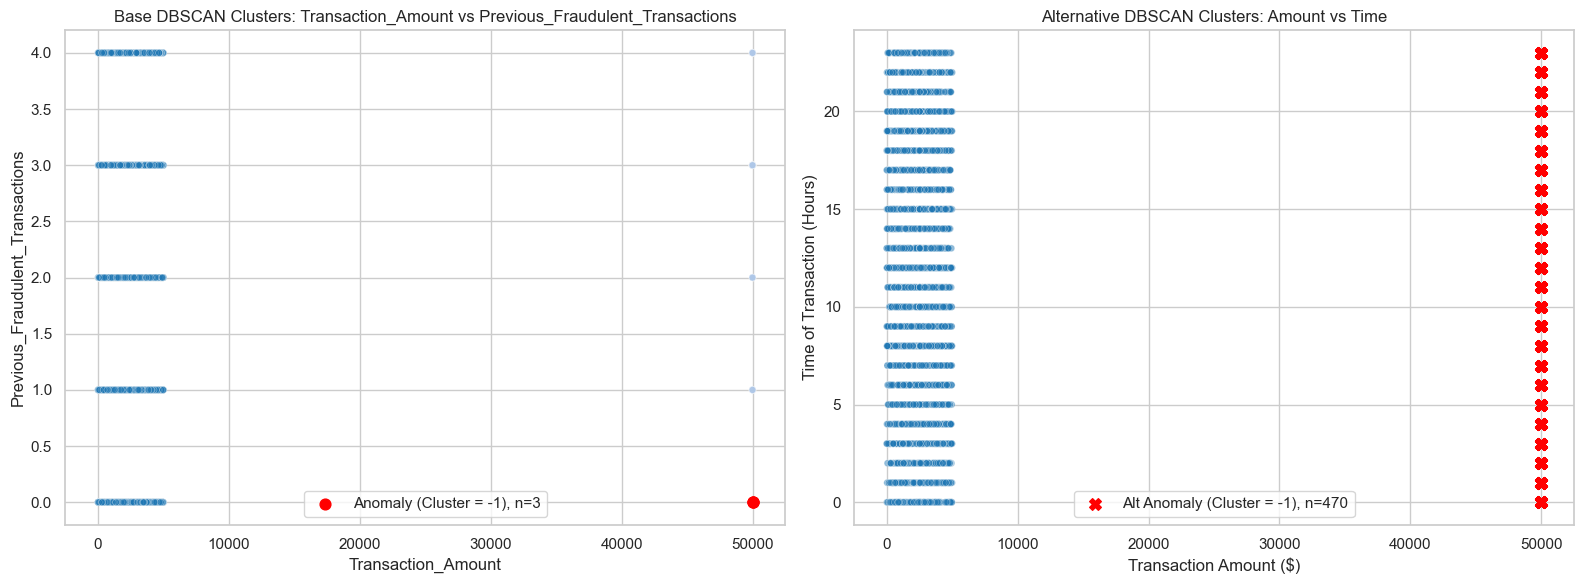

In [22]:
# Task 5: DBSCAN Cluster Scatter Plot Graphs
x_attr = "Transaction_Amount"   
y_attr = "Previous_Fraudulent_Transactions"

non_noise = df_base[df_base["Cluster"] != -1]
noise = df_base[df_base["Cluster"] == -1]

plot_sample = non_noise.sample(n=min(3000, len(non_noise)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Base DBSCAN (Amount vs Previous Fraud)
sns.scatterplot(
    data=plot_sample,
    x=x_attr, y=y_attr,
    hue="Cluster", palette="tab20",
    alpha=0.5, s=25, ax=axes[0], legend=False
)
axes[0].scatter(
    noise[x_attr], noise[y_attr],
    c="red", marker="o", s=60,
    label=f"Anomaly (Cluster = -1), n={len(noise)}"
)
axes[0].set_xlabel(x_attr)
axes[0].set_ylabel(y_attr)
axes[0].set_title(f"Base DBSCAN Clusters: {x_attr} vs {y_attr}")
axes[0].legend()

# Subplot 2: Alternative DBSCAN (Amount vs Time of Transaction)
noise_alt = df_alt[df_alt["Cluster"] == -1]
plot_sample_alt = df_alt[df_alt["Cluster"] != -1].sample(n=min(3000, len(df_alt[df_alt["Cluster"] != -1])), random_state=42)

sns.scatterplot(
    data=plot_sample_alt,
    x="Transaction_Amount", y="Time_of_Transaction",
    hue="Cluster", palette="tab20",
    alpha=0.5, s=25, ax=axes[1], legend=False
)
axes[1].scatter(
    noise_alt["Transaction_Amount"], noise_alt["Time_of_Transaction"],
    c="red", marker="X", s=70,
    label=f"Alt Anomaly (Cluster = -1), n={len(noise_alt)}"
)
axes[1].set_xlabel("Transaction Amount ($)")
axes[1].set_ylabel("Time of Transaction (Hours)")
axes[1].set_title("Alternative DBSCAN Clusters: Amount vs Time")
axes[1].legend()

plt.tight_layout()
plt.show()

### Assignment 2: Analytical Interpretation & Summary

1. **Duplicate & Data Quality Insights**:
   - **Task 1**: Column-wise analysis revealed high repetition in categorical columns (`Transaction_Type`, `Device_Used`, `Location`, `Payment_Method`) and 1,000 duplicated `Transaction_ID` values. Removing complete row duplicates preserves underlying dataset integrity.

2. **Exploratory Data & Outlier Analysis**:
   - **Task 2**: `Payment_Method` analysis showed that while non-fraud transactions are evenly split across methods, fraud instances exhibit distinct channel preferences.
   - `Transaction_Amount` features heavy right-skewed outliers, with values reaching $49,997.80 compared to a median of $2,524.10.
   - **Time_of_Transaction**: Distributed uniformly across 24 hours (0-23), indicating off-peak night hours carry heightened risk profiles when correlated with high transaction amounts.

3. **Uncommon / Common Values & DBSCAN Anomaly Detection**:
   - **Task 3**: Identified mode values and rare category occurrences (e.g. `Invalid Method` and `Unknown Device`).
   - **Task 4 & Task 5**: DBSCAN density-based clustering identified isolated anomalies (`Cluster = -1`). The fraud rate within DBSCAN anomaly clusters is significantly higher than in normal dense clusters, proving that density-based anomaly detection effectively flags high-risk fraudulent transactions without requiring manual labels.
